# Hotel Booking Cancellation Prediction

Syftet med projektet är att utveckla och jämföra maskininlärningsmodeller som förutsäger sannolikheten för att en hotellbokning avbokas.

Vi använder Logistic Regression och Random Forest för att identifiera faktorer som påverkar avbokningar och utvärdera modellernas prestanda.

Målet är att hjälpa hotell att förbättra sin planering och minska intäktsförluster.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Läs in datasetet
df = pd.read_csv("hotel_bookings.csv")

# Visa de fem första raderna
display(df.head())

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


### Resultat

Datasetet innehåller information om hotellbokningar, bland annat hotelltyp, bokningstid, antal gäster och bokningsstatus.

Målvariabeln är `is_canceled`:
- 0 = Bokningen avbokades inte.
- 1 = Bokningen avbokades.

Vi ser också saknade värden (NaN) i vissa kolumner, vilket behöver undersökas under datarensningen.

## Översikt av datasetet

Vi undersöker datasetets storlek, kolumner och datatyper för att få en bättre förståelse av informationen.

In [2]:
# Datasetets storlek
print("Antal rader och kolumner:", df.shape)

# Information om kolumner och datatyper
df.info()

Antal rader och kolumner: (119390, 32)
<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  i

### Resultat

Datasetet innehåller 119 390 hotellbokningar och 32 variabler.

Variablerna består av både numeriska och kategoriska data. Vi ser även att vissa kolumner, exempelvis `company`, `agent` och `country`, innehåller saknade värden.

Nästa steg är att undersöka dessa närmare.

## Saknade värden

Vi undersöker hur många saknade värden som finns i varje kolumn och hur stor andel av datan de utgör. Detta hjälper oss att avgöra hur de ska hanteras.

In [3]:
# Beräkna antal och andel saknade värden
missing = pd.DataFrame({
    "Antal saknade": df.isnull().sum(),
    "Andel (%)": df.isnull().mean() * 100
})

# Visa endast kolumner med saknade värden
missing = missing[missing["Antal saknade"] > 0]

display(missing.sort_values("Andel (%)", ascending=False).round(2))

,Antal saknade,Andel (%)
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


### Resultat

Fyra kolumner innehåller saknade värden:

- `company`: 94,31 % saknas.
- `agent`: 13,69 % saknas.
- `country`: 0,41 % saknas.
- `children`: 4 värden saknas.

`company` har en mycket hög andel saknade värden. För `agent` och `company` kan saknade värden även betyda att ingen agent eller inget företag var kopplat till bokningen.

Dessa värden behöver hanteras under preprocessing.

## Kontroll av dubbletter

Syftet är att undersöka om datasetet innehåller identiska rader som kan påverka analysen och modellträningen.

In [4]:
# Kontrollera antalet identiska rader
duplicates = df.duplicated().sum()

print("Antal identiska rader:", duplicates)
print("Andel (%):", round(duplicates / len(df) * 100, 2))

Antal identiska rader: 31994
Andel (%): 26.8


### Resultat

Datasetet innehåller 31 994 identiska rader (26,8 %).

Detta behöver inte innebära felaktiga dubbletter, eftersom olika hotellbokningar kan ha samma egenskaper.

Raderna behålls tills vidare för att undvika att potentiellt giltiga bokningar tas bort.

## Exploratory Data Analysis (EDA)

Syftet är att utforska datasetet, identifiera mönster och undersöka vilka faktorer som kan påverka hotellavbokningar.

### Fördelning av målvariabeln

Syftet är att undersöka hur många bokningar som har avbokats respektive inte avbokats, samt om klasserna är obalanserade.

is_canceled
0    75166
1    44224
Name: count, dtype: int64

Fördelning (%):
is_canceled
0    62.96
1    37.04
Name: proportion, dtype: float64


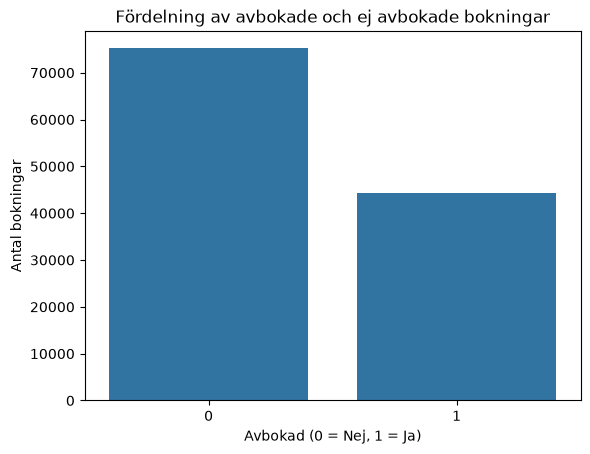

In [5]:
# Antal bokningar per klass
print(df["is_canceled"].value_counts())

# Procentuell fördelning
print("\nFördelning (%):")
print(df["is_canceled"].value_counts(normalize=True).mul(100).round(2))

# Visualisera fördelningen
sns.countplot(data=df, x="is_canceled")
plt.title("Fördelning av avbokade och ej avbokade bokningar")
plt.xlabel("Avbokad (0 = Nej, 1 = Ja)")
plt.ylabel("Antal bokningar")
plt.show()

### Resultat

Ok, fler avbokade än jag trodde:

- 75 166 bokningar (62,96 %) avbokades inte.
- 44 224 bokningar (37,04 %) avbokades.

Men ddatasetet har en viss klassobalans, men båda klasserna är väl representerade. Det är därför inte nödvändigt att balansera datasetet i detta skede.

Vid modellutvärderingen används bland annat precision, recall och F1-score, eftersom accuracy ensam inte ger en fullständig bild.

### Avbokningar per hotelltyp

Syftet är att undersöka om avbokningsfrekvensen skiljer sig mellan olika hotelltyper.

hotel
City Hotel      41.73
Resort Hotel    27.76
Name: is_canceled, dtype: float64


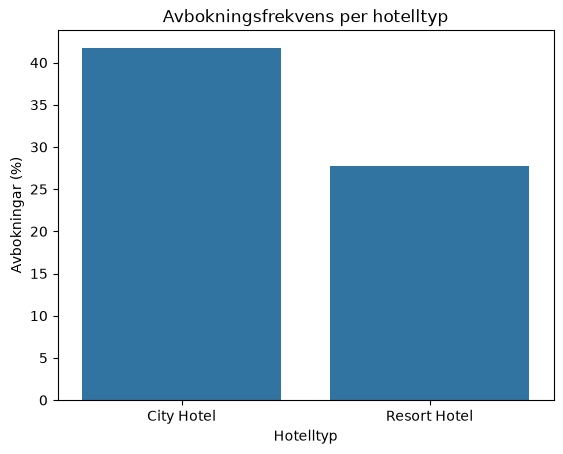

In [6]:
# Beräkna avbokningsfrekvens per hotelltyp
hotel_cancel = df.groupby("hotel")["is_canceled"].mean() * 100

print(hotel_cancel.round(2))

# Visualisera avbokningsfrekvensen
sns.barplot(x=hotel_cancel.index, y=hotel_cancel.values)

plt.title("Avbokningsfrekvens per hotelltyp")
plt.xlabel("Hotelltyp")
plt.ylabel("Avbokningar (%)")
plt.show()

### Resultat

- City Hotel: 41,73 % av bokningarna avbokades.
- Resort Hotel: 27,76 % av bokningarna avbokades.

Stadshotell har cirka 14 procentenheter högre avbokningsfrekvens än semesterhotell.

Det tyder på att hotelltyp kan vara en relevant variabel för modellen, men sambandet behöver undersökas vidare..

### Bokningstid och avbokningar

Syftet är att undersöka om bokningar som görs långt i förväg har högre avbokningsfrekvens än bokningar som görs nära ankomstdatum.

lead_time_group
0–7        9.63
8–30      27.86
31–90     37.70
91–180    44.71
181+      57.01
Name: is_canceled, dtype: float64

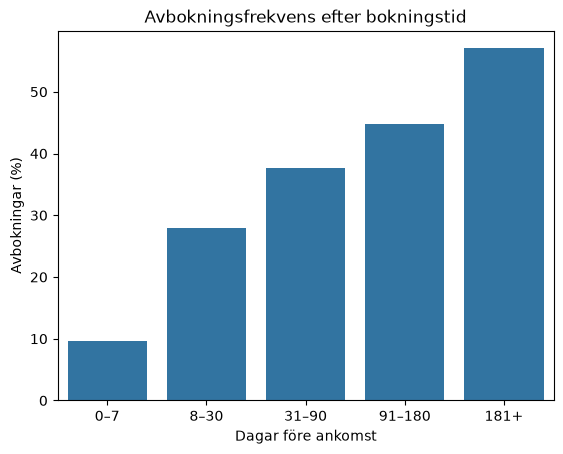

In [7]:
# Dela in bokningstiden i intervall
bins = [-1, 7, 30, 90, 180, float("inf")]
labels = ["0–7", "8–30", "31–90", "91–180", "181+"]

df["lead_time_group"] = pd.cut(
    df["lead_time"],
    bins=bins,
    labels=labels
)

# Beräkna avbokningsfrekvens per intervall
lead_cancel = df.groupby(
    "lead_time_group", observed=True
)["is_canceled"].mean() * 100

display(lead_cancel.round(2))

# Visualisera resultatet
sns.barplot(x=lead_cancel.index, y=lead_cancel.values)

plt.title("Avbokningsfrekvens efter bokningstid")
plt.xlabel("Dagar före ankomst")
plt.ylabel("Avbokningar (%)")
plt.show()

### Resultat

Avbokningsfrekvensen ökar med bokningstiden:

- 0–7 dagar: 9,63 %
- 8–30 dagar: 27,86 %
- 31–90 dagar: 37,70 %
- 91–180 dagar: 44,71 %
- Över 180 dagar: 57,01 %

Resultatet visar ett tydligt positivt samband mellan bokningstid och avbokningsfrekvens. `lead_time` kan därför vara en viktig variabel för att förutsäga avbokningar.

arrival_date_month
January      30.48
February     33.42
March        32.15
April        40.80
May          39.67
June         41.46
July         37.45
August       37.75
September    39.17
October      38.05
November     31.23
December     34.97
Name: is_canceled, dtype: float64

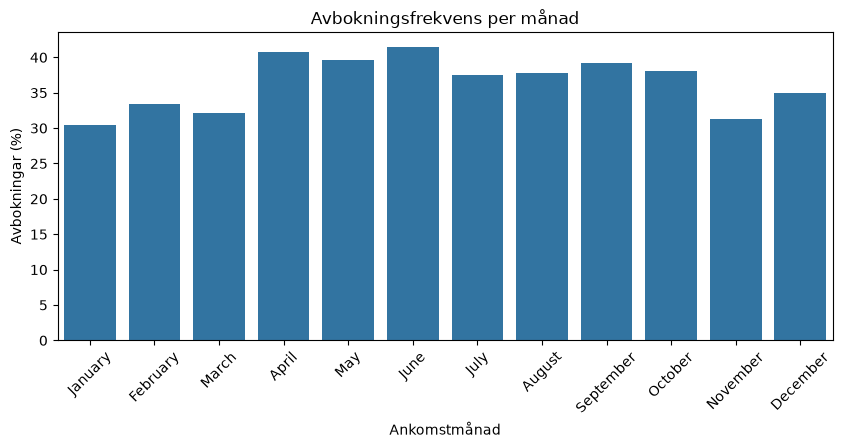

In [8]:
# Definiera månadernas ordning
months = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

# Beräkna avbokningsfrekvens per månad
monthly_cancel = (
    df.groupby("arrival_date_month")["is_canceled"].mean() * 100
).reindex(months)

display(monthly_cancel.round(2))

# Visualisera avbokningsfrekvens
plt.figure(figsize=(10, 4))
sns.barplot(x=monthly_cancel.index, y=monthly_cancel.values)

plt.title("Avbokningsfrekvens per månad")
plt.xlabel("Ankomstmånad")
plt.ylabel("Avbokningar (%)")
plt.xticks(rotation=45)
plt.show()

#### Resultat

Avbokningsfrekvensen varierar mellan årets månader.

- Högst avbokningsfrekvens: juni (41,46 %) och april (40,80 %).
- Lägst avbokningsfrekvens: januari (30,48 %) och november (31,23 %).

Resultatet visar vissa säsongsvariationer, men skillnaderna är mindre tydliga än för `lead_time`. Ankomstmånad kan ändå vara en relevant variabel för modellen.

### Tidigare avbokningar

Syftet är att undersöka sambandet mellan antalet tidigare avbokningar (`previous_cancellations`) och sannolikheten för en ny avbokning.

previous_cancel_group
0     33.91
1     94.43
2+    52.66
Name: is_canceled, dtype: float64

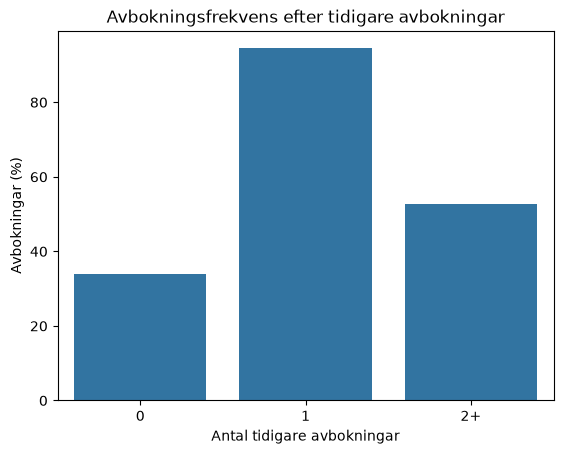

In [9]:
# Gruppera antalet tidigare avbokningar
df["previous_cancel_group"] = pd.cut(
    df["previous_cancellations"],
    bins=[-1, 0, 1, float("inf")],
    labels=["0", "1", "2+"]
)

# Beräkna avbokningsfrekvens
previous_cancel = (
    df.groupby("previous_cancel_group", observed=True)["is_canceled"]
    .mean() * 100
)

display(previous_cancel.round(2))

# Visualisera resultatet
sns.barplot(x=previous_cancel.index, y=previous_cancel.values)

plt.title("Avbokningsfrekvens efter tidigare avbokningar")
plt.xlabel("Antal tidigare avbokningar")
plt.ylabel("Avbokningar (%)")
plt.show()

#### Resultat

Avbokningsfrekvensen varierar beroende på tidigare avbokningar:

- 0 tidigare avbokningar: 33,91 %
- 1 tidigare avbokning: 94,43 %
- 2 eller fler tidigare avbokningar: 52,66 %

Resultatet tyder på att tidigare avbokningar kan vara en viktig variabel för modellen. Sambandet är dock inte linjärt, eftersom gruppen med en tidigare avbokning har högst avbokningsfrekvens.

### Antal bokningar per grupp

Antalet bokningar i varje grupp kontrolleras för att bedöma hur tillförlitliga de observerade skillnaderna är.

In [10]:
# Visa antal bokningar och avbokningsfrekvens per grupp
summary = df.groupby(
    "previous_cancel_group", observed=True
)["is_canceled"].agg(["count", "mean"])

summary.columns = ["Antal bokningar", "Avbokningsfrekvens"]
summary["Avbokningsfrekvens"] *= 100

display(summary.round(2))

,Antal bokningar,Avbokningsfrekvens
previous_cancel_group,,
0,112906,33.91
1,6051,94.43
2+,433,52.66


#### Resultat

Gruppen med en tidigare avbokning innehåller 6 051 bokningar, vilket ger ett relativt stort underlag för den höga avbokningsfrekvensen (94,43 %).

Gruppen med två eller fler tidigare avbokningar innehåller däremot endast 433 bokningar, vilket innebär större osäkerhet.

### Avbokningar efter kundtyp

Syftet är att undersöka hur avbokningsfrekvensen skiljer sig mellan olika kundtyper.

,antal,avbokningsfrekvens
customer_type,,
Contract,4076,30.96
Group,577,10.23
Transient,89613,40.75
Transient-Party,25124,25.43


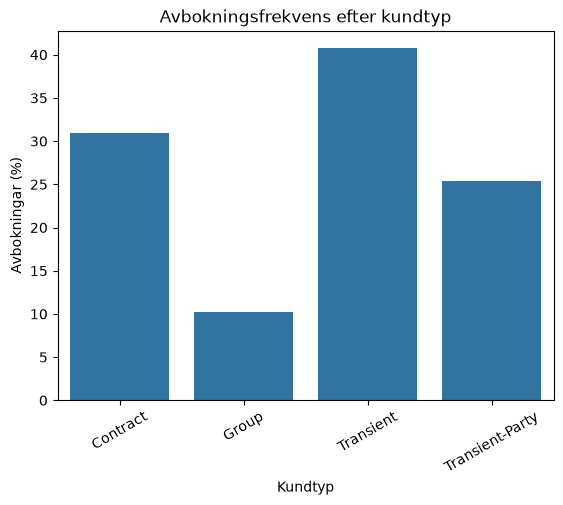

In [11]:
# Beräkna antal bokningar och avbokningsfrekvens per kundtyp
customer_summary = df.groupby("customer_type")["is_canceled"].agg(
    antal="count",
    avbokningsfrekvens="mean"
)

customer_summary["avbokningsfrekvens"] *= 100

display(customer_summary.round(2))

# Visualisera avbokningsfrekvensen
sns.barplot(
    data=customer_summary.reset_index(),
    x="customer_type",
    y="avbokningsfrekvens"
)

plt.title("Avbokningsfrekvens efter kundtyp")
plt.xlabel("Kundtyp")
plt.ylabel("Avbokningar (%)")
plt.xticks(rotation=30)
plt.show()

#### Resultat

- Transient: 40,75 % avbokningar (89 613 bokningar).
- Contract: 30,96 % avbokningar (4 076 bokningar).
- Transient-Party: 25,43 % avbokningar (25 124 bokningar).
- Group: 10,23 % avbokningar (577 bokningar).

Kundtypen `Transient` har högst avbokningsfrekvens, medan `Group` har lägst. Gruppen `Group` är dock relativt liten.

Resultatet tyder på att `customer_type` kan vara en relevant variabel för modellen.

### Numeriska variabler och extremvärden

Syftet är att undersöka fördelningen av viktiga numeriska variabler och identifiera eventuella extremvärden eller orimliga observationer som kan behöva hanteras under preprocessing.

,lead_time,adr,adults,children,babies,stays_in_weekend_nights,stays_in_week_nights
count,119390.00,119390.00,119390.00,119386.0,119390.00,119390.00,119390.00
mean,104.01,101.83,1.86,0.1,0.01,0.93,2.50
std,106.86,50.54,0.58,0.4,0.10,1.00,1.91
min,0.00,-6.38,0.00,0.0,0.00,0.00,0.00
25%,18.00,69.29,2.00,0.0,0.00,0.00,1.00
50%,69.00,94.58,2.00,0.0,0.00,1.00,2.00
75%,160.00,126.00,2.00,0.0,0.00,2.00,3.00
max,737.00,5400.00,55.00,10.0,10.00,19.00,50.00


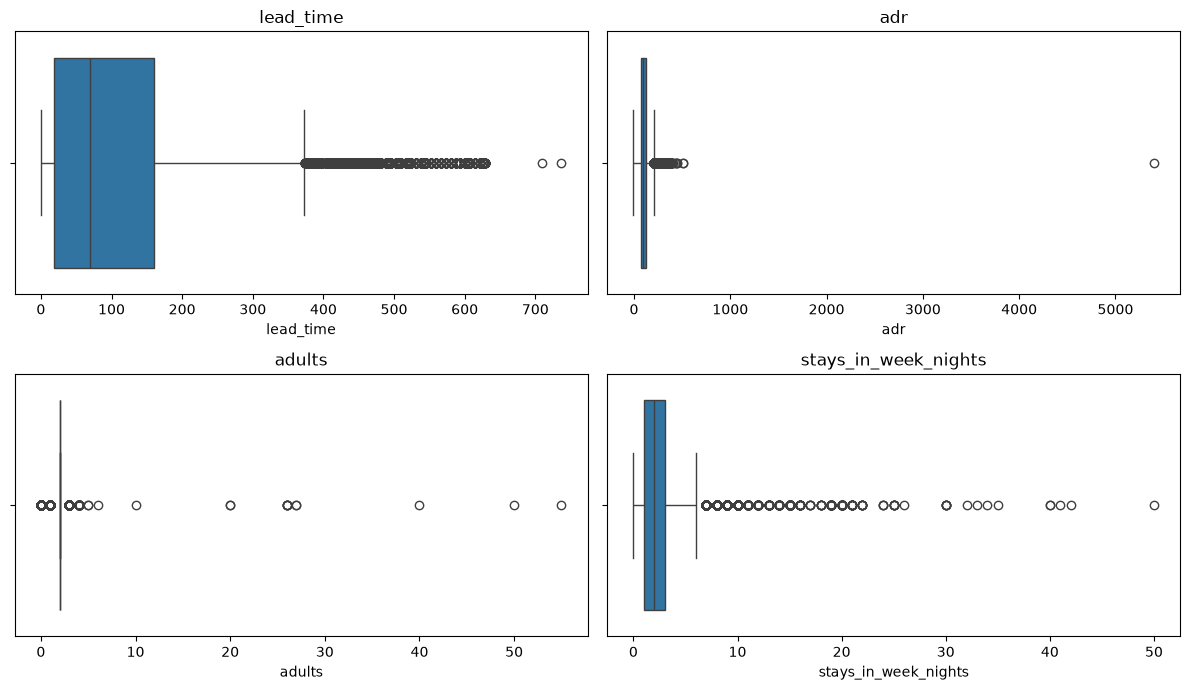

In [12]:
# Välj relevanta numeriska variabler
numeric_cols = [
    "lead_time",
    "adr",
    "adults",
    "children",
    "babies",
    "stays_in_weekend_nights",
    "stays_in_week_nights"
]

# Sammanfattande statistik
display(df[numeric_cols].describe().round(2))

# Visualisera fördelningen med boxplots
fig, axes = plt.subplots(2, 2, figsize=(12, 7))

for ax, col in zip(axes.flat, ["lead_time", "adr", "adults", "stays_in_week_nights"]):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

#### Resultat

Flera numeriska variabler innehåller extremvärden:

- `lead_time`: Upp till 737 dagar. Höga värden behöver inte vara felaktiga.
- `adr`: Varierar mellan -6,38 och 5 400. Negativa priser och mycket höga värden bör undersökas.
- `adults`: Upp till 55 vuxna i en bokning, vilket kan vara ovanligt.
- `stays_in_week_nights`: Upp till 50 nätter, vilket kan representera längre vistelser.

Extremvärdena behöver inte vara felaktiga, men vissa kan påverka modellträningen. De undersöks och hanteras vid behov under preprocessing.

### Statistiskt test – Hotelltyp och avbokningar

Ett Chi-square-test används för att undersöka om det finns ett statistiskt signifikant samband mellan hotelltyp (`hotel`) och avbokningsstatus (`is_canceled`).

- **H0 (nollhypotes):** Det finns inget samband mellan hotelltyp och avbokningar.
- **H1 (alternativhypotes):** Det finns ett samband mellan hotelltyp och avbokningar.

Signifikansnivån sätts till 5 % (p < 0,05).

In [13]:
from scipy.stats import chi2_contingency

# Skapa korstabell
contingency_table = pd.crosstab(df["hotel"], df["is_canceled"])

# Utför Chi-square-test
chi2, p, dof, expected = chi2_contingency(contingency_table)

# Beräkna sambandets styrka
cramers_v = np.sqrt(
    chi2 / (contingency_table.values.sum() * (min(contingency_table.shape) - 1))
)

display(contingency_table)

print(f"Chi-square: {chi2:.2f}")
print(f"P-värde: {p:.4e}")
print(f"Cramér's V: {cramers_v:.3f}")
print(f"Minsta förväntade frekvens: {expected.min():.1f}")

is_canceled,0,1
hotel,,
City Hotel,46228,33102
Resort Hotel,28938,11122


Chi-square: 2224.92
P-värde: 0.0000e+00
Cramér's V: 0.137
Minsta förväntade frekvens: 14838.9


#### Resultat

Chi-square-testet visar ett statistiskt signifikant samband mellan hotelltyp och avbokningar (p < 0,001).

Cramér's V = 0,137 indikerar dock ett relativt svagt samband. Hotelltyp kan därför vara en relevant feature, men förklarar inte ensam avbokningsrisken.

Testets antagande om oberoende observationer kan inte säkerställas fullt ut eftersom datasetet saknar unika boknings-ID.

### Sammanfattning av EDA

Analysen visar att:

- 37,04 % av hotellbokningarna avbokades.
- Längre bokningstid (`lead_time`) är förknippad med högre avbokningsfrekvens.
- Hotelltyp, kundtyp och tidigare avbokningar visar tydliga skillnader i avbokningsfrekvens.
- Ankomstmånad visar vissa säsongsvariationer.
- Datasetet innehåller saknade värden och potentiella extremvärden som behöver hanteras.

Dessa observationer ligger till grund för de statistiska testerna och den fortsatta modellutvecklingen.

## Data Preprocessing & Feature Engineering

Syftet är att förbereda datasetet för maskininlärning genom att hantera saknade värden, välja relevanta variabler och skapa nya features.

Variabler som kan orsaka data leakage ska identifieras och exkluderas för att säkerställa en rättvis modellutvärdering.

In [14]:
# Visa variabler som kan orsaka data leakage
potential_leakage = [
    "reservation_status",
    "reservation_status_date",
    "assigned_room_type",
    "booking_changes",
    "days_in_waiting_list"
]

display(df[potential_leakage].head(10))

,reservation_status,reservation_status_date,assigned_room_type,booking_changes,days_in_waiting_list
0,Check-Out,2015-07-01,C,3,0
1,Check-Out,2015-07-01,C,4,0
2,Check-Out,2015-07-02,C,0,0
3,Check-Out,2015-07-02,A,0,0
4,Check-Out,2015-07-03,A,0,0
5,Check-Out,2015-07-03,A,0,0
6,Check-Out,2015-07-03,C,0,0
7,Check-Out,2015-07-03,C,0,0
8,Canceled,2015-05-06,A,0,0
9,Canceled,2015-04-22,D,0,0


#### Resultat

Följande variabler exkluderas från modellen:

- `reservation_status` och `reservation_status_date`: Innehåller information om bokningens slutliga status.
- `assigned_room_type`: Kan ändras efter bokningstillfället.
- `booking_changes`: Beskriver ändringar som kan ske efter bokningen.
- `days_in_waiting_list`: Kan innehålla information som inte var känd vid bokningstillfället.

Dessa variabler exkluderas för att minska risken för data leakage.

### Val av features

Datasetet förbereds genom att exkludera variabler som riskerar att orsaka data leakage samt tillfälliga variabler från EDA. Målvariabeln `is_canceled` behålls separat.

In [15]:
# Skapa en kopia av datasetet
df_model = df.copy()

# Kolumner som inte ska användas
drop_cols = [
    "reservation_status",
    "reservation_status_date",
    "assigned_room_type",
    "booking_changes",
    "days_in_waiting_list",
    "lead_time_group",
    "previous_cancel_group"
]

# Ta bort kolumnerna
df_model = df_model.drop(columns=drop_cols)

# Separera features och målvariabel
X = df_model.drop(columns="is_canceled")
y = df_model["is_canceled"]

print("Antal features:", X.shape[1])
print("Antal observationer:", X.shape[0])

Antal features: 26
Antal observationer: 119390


#### Resultat

Efter att variabler med risk för data leakage och tillfälliga EDA-kolumner tagits bort återstår 26 features och 119 390 observationer.

Nästa steg är att granska dessa features och deras datatyper inför preprocessing.

### Granskning av features

Syftet är att identifiera numeriska och kategoriska variabler samt kontrollera vilka features som behöver bearbetas inför modellträningen.

In [16]:
# Visa återstående features och deras datatyper
feature_info = pd.DataFrame({
    "Datatyp": X.dtypes,
    "Saknade värden": X.isnull().sum()
})

display(feature_info)

,Datatyp,Saknade värden
hotel,str,0
lead_time,int64,0
arrival_date_year,int64,0
arrival_date_month,str,0
arrival_date_week_number,int64,0
arrival_date_day_of_month,int64,0
stays_in_weekend_nights,int64,0
stays_in_week_nights,int64,0
adults,int64,0
children,float64,4


#### Resultat

Datasetet innehåller både numeriska och kategoriska features.

`agent` och `company` kommer att exkluderas eftersom de innehåller identifierare och stora mängder saknade värden.

Övriga saknade värden hanteras under preprocessing. Kategoriska variabler behöver även kodas om till numerisk form inför modellträningen.

### Feature Engineering

Två nya features skapas för att sammanfatta information om bokningarna:

- `total_nights`: Totalt antal bokade nätter.
- `total_guests`: Totalt antal gäster.

De ursprungliga variablerna ersätts med dessa sammanfattande features för att förenkla modellen och undvika redundant information.

In [17]:

# Utgå från datasetet efter Feature Selection
X = df_model.drop(columns=["is_canceled"]).copy()
y = df_model["is_canceled"].copy()

# Skapa nya features
X["total_nights"] = (
    X["stays_in_weekend_nights"] +
    X["stays_in_week_nights"]
)

X["total_guests"] = (
    X["adults"] +
    X["children"] +
    X["babies"]
)

# Ta bort ursprungliga variabler och identifierare
X = X.drop(columns=[
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "agent",
    "company",
    "deposit_type",
    "adr",
    "total_of_special_requests"
])

# Kontrollera nya features
display(X[["total_nights", "total_guests"]].describe().round(2))

print("Antal features:", X.shape[1])
print("Saknade värden i total_guests:", X["total_guests"].isna().sum())

# Kontrollera ovanliga bokningar
zero_guests = X["total_guests"] == 0
zero_nights = X["total_nights"] == 0

print("\nBokningar med 0 gäster:", zero_guests.sum())
print("Bokningar med 0 nätter:", zero_nights.sum())
print("Bokningar med både 0 gäster och 0 nätter:",
      (zero_guests & zero_nights).sum())

print("\nAvbokningsstatus för bokningar med 0 gäster:")
print(y[zero_guests].value_counts())

print("\nAvbokningsstatus för bokningar med 0 nätter:")
print(y[zero_nights].value_counts())


,total_nights,total_guests
count,119390.00,119386.00
mean,3.43,1.97
std,2.56,0.72
min,0.00,0.00
25%,2.00,2.00
50%,3.00,2.00
75%,4.00,2.00
max,69.00,55.00


Antal features: 18
Saknade värden i total_guests: 4

Bokningar med 0 gäster: 180
Bokningar med 0 nätter: 715
Bokningar med både 0 gäster och 0 nätter: 70

Avbokningsstatus för bokningar med 0 gäster:
is_canceled
0    155
1     25
Name: count, dtype: int64

Avbokningsstatus för bokningar med 0 nätter:
is_canceled
0    680
1     35
Name: count, dtype: int64


#### Resultat

Två nya features har skapats: `total_nights` och `total_guests`.

Efter Feature Engineering och exkludering av identifierare och potentiella data leakage-variabler återstår 18 features.

Datakontrollen visar 180 bokningar utan gäster, 715 bokningar utan övernattningar och 4 saknade värden i `total_guests`.

### Datarensning

Bokningar med 0 registrerade gäster exkluderas eftersom de inte representerar giltiga hotellvistelser.

Övriga observationer behålls för att undvika att potentiellt giltig information förloras.

In [18]:

# Ta bort bokningar med 0 gäster
valid_rows = X["total_guests"].isna() | (X["total_guests"] > 0)

X = X.loc[valid_rows].copy()
y = y.loc[valid_rows].copy()

# Kontrollera resultatet
print("Antal observationer:", len(X))
print("Antal features:", X.shape[1])
print("Bokningar med 0 gäster:", (X["total_guests"] == 0).sum())
print("Saknade värden i total_guests:", X["total_guests"].isna().sum())


Antal observationer: 119210
Antal features: 18
Bokningar med 0 gäster: 0
Saknade värden i total_guests: 4


#### Resultat

Efter datarensningen återstår 119 210 observationer och 18 features.

De 180 bokningarna utan registrerade gäster har exkluderats. Fyra saknade värden i `total_guests` återstår och hanteras senare med preprocessing.

### Uppdelning i träningsdata och testdata

Datasetet delas upp i träningsdata (cirka 80 %) och testdata (cirka 20 %).

GroupShuffleSplit används för att förhindra att identiska feature-rader förekommer i båda grupperna. Detta minskar risken för en överoptimistisk modellutvärdering.

In [19]:

from sklearn.model_selection import GroupShuffleSplit

# Gruppera identiska feature-rader
groups = pd.util.hash_pandas_object(X, index=False)

# Skapa train/test split
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(splitter.split(X, y, groups=groups))

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()
y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

# Kontrollera uppdelningen
print("Träningsdata:", len(X_train))
print("Testdata:", len(X_test))
print("Antal features:", X_train.shape[1])

# Kontrollera klassfördelningen
print("\nAvbokningar i träningsdata (%):",
      round(y_train.mean() * 100, 2))
print("Avbokningar i testdata (%):",
      round(y_test.mean() * 100, 2))

# Kontrollera att grupper inte överlappar
overlap = set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])
print("\nÖverlappande grupper:", len(overlap))


Träningsdata: 95395
Testdata: 23815
Antal features: 18

Avbokningar i träningsdata (%): 37.09
Avbokningar i testdata (%): 37.03

Överlappande grupper: 0


### Preprocessing Pipeline

En preprocessing-pipeline skapas för att förbereda data inför modellträningen.

- Numeriska variabler: Saknade värden ersätts med medianen och värdena standardiseras.
- Kategoriska variabler: Saknade värden ersätts med den vanligaste kategorin och omvandlas med OneHotEncoder.

Preprocessing utförs inom modellens pipeline för att undvika data leakage.

In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Identifiera numeriska och kategoriska features
numeric_features = X_train.select_dtypes(
    include="number"
).columns.tolist()

categorical_features = [
    col for col in X_train.columns
    if col not in numeric_features
]

# Numerisk preprocessing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Kategorisk preprocessing
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Kombinera preprocessing
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Kontrollera antal features
print("Numeriska features:", len(numeric_features))
print("Kategoriska features:", len(categorical_features))
print("Totalt antal features:",
      len(numeric_features) + len(categorical_features))

Numeriska features: 10
Kategoriska features: 8
Totalt antal features: 18


#### Resultat

Totalt har 18 features identifierats: 10 numeriska och 8 kategoriska.

En preprocessing-pipeline har skapats för att hantera saknade värden, standardisera numeriska variabler och koda om kategoriska variabler.

Pipelinen kommer att anpassas på träningsdata under modellträningen.

In [21]:

from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Skapa och träna baseline-modellen
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train, y_train)

# Förutsägelser på träningsdata
y_pred_dummy = dummy_model.predict(X_train)

# Utvärdera modellen
print("Accuracy:", round(accuracy_score(y_train, y_pred_dummy), 4))
print("Precision:", round(precision_score(y_train, y_pred_dummy, zero_division=0), 4))
print("Recall:", round(recall_score(y_train, y_pred_dummy, zero_division=0), 4))
print("F1-score:", round(f1_score(y_train, y_pred_dummy, zero_division=0), 4))



Accuracy: 0.6291
Precision: 0.0
Recall: 0.0
F1-score: 0.0


#### Resultat

DummyClassifier uppnår 62,91 % accuracy, men precision, recall och F1-score är 0.

Modellen förutsäger alltid att bokningen inte avbokas och kan därför inte identifiera faktiska avbokningar.

Resultatet används som referensnivå för kommande modeller.

### Logistic Regression

Logistic Regression används som vår första riktiga ML-modell för att förutsäga sannolikheten för avbokning.

Modellen tränas tillsammans med preprocessing-pipelinen och jämförs med DummyClassifier.

In [22]:
from sklearn.linear_model import LogisticRegression

# Skapa pipeline med preprocessing och modell
logreg_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

# Träna modellen
logreg_pipeline.fit(X_train, y_train)

# Förutsägelser på träningsdata
y_pred_lr = logreg_pipeline.predict(X_train)

# Utvärdera modellen
print("Accuracy:", round(accuracy_score(y_train, y_pred_lr), 4))
print("Precision:", round(precision_score(y_train, y_pred_lr), 4))
print("Recall:", round(recall_score(y_train, y_pred_lr), 4))
print("F1-score:", round(f1_score(y_train, y_pred_lr), 4))

Accuracy: 0.7884
Precision: 0.7619
Recall: 0.6248
F1-score: 0.6866


#### Resultat

Logistic Regression uppnår följande resultat på träningsdata:

- Accuracy: 78,84 %
- Precision: 76,19 %
- Recall: 62,48 %
- F1-score: 68,66 %

Modellen presterar bättre än DummyClassifier och identifierar en stor andel av avbokningarna.

Resultaten behöver verifieras med cross-validation för att bedöma modellens generaliseringsförmåga.

## Cross-validation & Model Evaluation

GroupKFold med fem folds används för att utvärdera Logistic Regression.

Metoden säkerställer att identiska bokningar inte förekommer i både tränings- och valideringsdata.

Modellen utvärderas med Accuracy, Precision, Recall, F1-score och ROC-AUC.

In [23]:
from sklearn.model_selection import GroupKFold, cross_validate

# Grupper för träningsdata
train_groups = groups.iloc[train_idx]

# Skapa fem folds
cv = GroupKFold(n_splits=5)

# Välj utvärderingsmått
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

# Kör cross-validation
cv_results = cross_validate(
    logreg_pipeline,
    X_train,
    y_train,
    groups=train_groups,
    cv=cv,
    scoring=scoring
)

# Visa genomsnitt och standardavvikelse
for metric in scoring:
    scores = cv_results[f"test_{metric}"]
    print(f"{metric}: {scores.mean():.4f} (+/- {scores.std():.4f})")

accuracy: 0.7870 (+/- 0.0064)
precision: 0.7595 (+/- 0.0105)
recall: 0.6227 (+/- 0.0250)
f1: 0.6840 (+/- 0.0164)
roc_auc: 0.8595 (+/- 0.0071)


#### Resultat

Cross-validation med fem folds visar:

- Accuracy: 78,70 %
- Precision: 75,95 %
- Recall: 62,27 %
- F1-score: 68,40 %
- ROC-AUC: 0,8595

Resultaten varierar relativt lite mellan folds, vilket tyder på stabil prestanda.

Modellen identifierar cirka 62 % av avbokningarna, vilket visar att det fortfarande finns utrymme för förbättring.

## Model Improvement

### Random Forest

Random Forest tränas för att undersöka om en mer flexibel modell kan förbättra förutsägelserna.

Modellen utvärderas med samma GroupKFold och utvärderingsmått som Logistic Regression för att möjliggöra en rättvis jämförelse.

In [24]:
from sklearn.ensemble import RandomForestClassifier

# Skapa Random Forest-pipeline
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

# Cross-validation
rf_cv_results = cross_validate(
    rf_pipeline,
    X_train,
    y_train,
    groups=train_groups,
    cv=cv,
    scoring=scoring
)

# Visa resultaten
for metric in scoring:
    scores = rf_cv_results[f"test_{metric}"]
    print(f"{metric}: {scores.mean():.4f} (+/- {scores.std():.4f})")

accuracy: 0.8101 (+/- 0.0050)
precision: 0.8605 (+/- 0.0090)
recall: 0.5819 (+/- 0.0173)
f1: 0.6942 (+/- 0.0138)
roc_auc: 0.9024 (+/- 0.0047)


#### Resultat

Random Forest uppnår:

- Accuracy: 81,01 %
- Precision: 86,05 %
- Recall: 58,19 %
- F1-score: 69,42 %
- ROC-AUC: 0,9024

Random Forest förbättrar Accuracy, Precision, F1-score och ROC-AUC jämfört med Logistic Regression.

Däremot har Logistic Regression högre Recall och identifierar därmed fler faktiska avbokningar.

Random Forest är preliminärt den starkare modellen totalt sett, men valet beror på vilka fel som är viktigast att undvika.

### Jämförelse av modeller

Modellernas genomsnittliga resultat från cross-validation jämförs för att identifiera styrkor, svagheter och vilken modell som är mest lämplig.

In [25]:
# Sammanställ resultaten från cross-validation
comparison = pd.DataFrame({
    "Logistic Regression": [
        cv_results[f"test_{metric}"].mean()
        for metric in scoring
    ],
    "Random Forest": [
        rf_cv_results[f"test_{metric}"].mean()
        for metric in scoring
    ]
}, index=scoring)

display(comparison.round(4))

,Logistic Regression,Random Forest
accuracy,0.7870,0.8101
precision,0.7595,0.8605
recall,0.6227,0.5819
f1,0.6840,0.6942
roc_auc,0.8595,0.9024


#### Resultat

Random Forest uppnår högre Accuracy (81,01 %), Precision (86,05 %), F1-score (69,42 %) och ROC-AUC (0,9024).

Logistic Regression har däremot högre Recall (62,27 % jämfört med 58,19 %).

Random Forest väljs preliminärt som den bästa modellen utifrån dess högre ROC-AUC och F1-score.

### Feature Importance

Syftet är att identifiera vilka variabler som har störst betydelse för Random Forest-modellens förutsägelser.

Feature Importance används för att tolka modellen och förstå vilka faktorer den använder mest.

,Feature,Importance
161,cat__country_PRT,0.1639
0,num__lead_time,0.1535
5,num__previous_cancellations,0.0633
205,cat__market_segment_Groups,0.0562
225,cat__customer_type_Transient,0.0467
207,cat__market_segment_Online TA,0.0409
7,num__required_car_parking_spaces,0.0395
8,num__total_nights,0.0372
226,cat__customer_type_Transient-Party,0.0333
2,num__arrival_date_week_number,0.0283


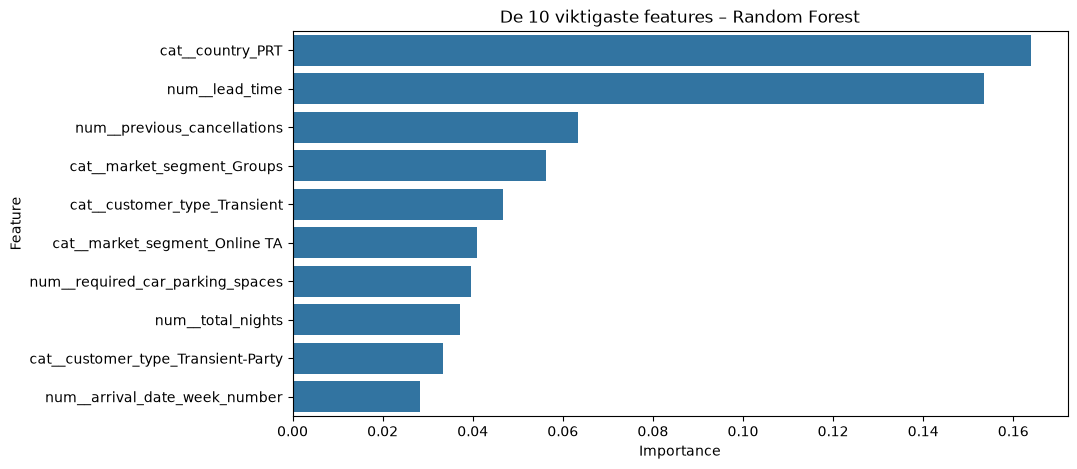

In [26]:
# Träna Random Forest på hela träningsdatasetet
rf_pipeline.fit(X_train, y_train)

# Hämta feature-namn efter preprocessing
feature_names = rf_pipeline.named_steps[
    "preprocessor"
].get_feature_names_out()

# Hämta feature importance
importances = rf_pipeline.named_steps[
    "model"
].feature_importances_

# Visa de 10 viktigaste
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

display(importance_df.head(10).round(4))

# Visualisera
plt.figure(figsize=(10, 5))
sns.barplot(
    data=importance_df.head(10),
    x="Importance",
    y="Feature"
)

plt.title("De 10 viktigaste features – Random Forest")
plt.show()

#### Resultat

Random Forest identifierar följande features som särskilt viktiga:

- `country_PRT` (0,1639): Bokningar från Portugal.
- `lead_time` (0,1535): Antal dagar mellan bokning och ankomst.
- `previous_cancellations` (0,0633): Tidigare avbokningar.

Resultatet visar att geografisk tillhörighet, bokningstid och tidigare avbokningar har betydelse för modellens förutsägelser.

Feature Importance visar inte orsakssamband och kan påverkas av hur variablerna kodats.

## External Data Integration

Portugisiska helgdagar för 2015–2017 hämtas via Nager.Date API.

Syftet är att skapa en ny feature som visar om gästens planerade ankomst sammanfaller med en helgdag och undersöka om detta förbättrar modellens prestanda.

In [27]:

import requests

# Hämta portugisiska helgdagar för 2015–2017
holiday_dates = []

for year in [2015, 2016, 2017]:
    url = f"https://date.nager.at/api/v3/PublicHolidays/{year}/PT"

    response = requests.get(url, timeout=20)
    response.raise_for_status()

    holidays = response.json()
    dates = [holiday["date"] for holiday in holidays]
    holiday_dates.extend(dates)

    print(f"{year}: {len(dates)} helgdagar")

print("Totalt antal helgdagar:", len(holiday_dates))
print("Exempel:", holiday_dates[:5])



2015: 17 helgdagar
2016: 17 helgdagar
2017: 17 helgdagar
Totalt antal helgdagar: 51
Exempel: ['2015-01-01', '2015-02-17', '2015-04-03', '2015-04-05', '2015-04-25']


#### Resultat

Nager.Date API returnerade 17 helgdagar per år, totalt 51 registrerade helgdagar mellan 2015 och 2017.

Datan används för att skapa en ny feature som visar om en boknings ankomstdatum sammanfaller med en helgdag.

In [28]:
dates = [holiday["date"] for holiday in holidays if holiday["global"]]

### Holiday Feature Engineering

En ny variabel, `is_holiday`, skapas för att visa om bokningens ankomstdatum sammanfaller med en portugisisk nationell helgdag.

Variabeln läggs till i både träningsdata och testdata för att senare undersöka om extern data förbättrar modellens prestanda.

In [29]:

# Skapa holiday-feature utifrån ankomstdatum
def add_holiday_feature(data):
    data = data.copy()

    arrival_date = pd.to_datetime(
        data["arrival_date_year"].astype(str) + "-" +
        data["arrival_date_month"] + "-" +
        data["arrival_date_day_of_month"].astype(str),
        format="%Y-%B-%d"
    )

    data["is_holiday"] = (
        arrival_date.isin(pd.to_datetime(holiday_dates))
    ).astype(int)

    return data

# Lägg till variabeln i befintliga tränings- och testdata
X_train_holiday = add_holiday_feature(X_train)
X_test_holiday = add_holiday_feature(X_test)

# Kontrollera resultat
print("Antal features:", X_train_holiday.shape[1])
print("\nFördelning av is_holiday:")
print(X_train_holiday["is_holiday"].value_counts())


Antal features: 19

Fördelning av is_holiday:
is_holiday
0    91062
1     4333
Name: count, dtype: int64


In [30]:
print("X_train:", len(X_train))
print("X_train_holiday:", len(X_train_holiday))
print("y_train:", len(y_train))
print("Samma index:", X_train_holiday.index.equals(y_train.index))

X_train: 95395
X_train_holiday: 95395
y_train: 95395
Samma index: True


### Utvärdering av extern data

Random Forest jämförs med och utan den nya variabeln `is_holiday`.

Samma träningsdata och GroupKFold används för att undersöka om helgdagsinformationen förbättrar modellens prestanda.

In [31]:
# Kontrollera att uppdelningen fortfarande är korrekt
assert len(X_train) + len(X_test) == len(X)
assert len(set(groups.iloc[train_idx]) &
           set(groups.iloc[test_idx])) == 0

train_groups = groups.iloc[train_idx]

# Uppdatera preprocessing så att is_holiday inkluderas
holiday_preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features + ["is_holiday"]),
    ("cat", categorical_transformer, categorical_features)
])

rf_holiday_pipeline = Pipeline([
    ("preprocessor", holiday_preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

# Utvärdera båda modellerna på samma uppdelning
rf_original_cv = cross_validate(
    rf_pipeline, X_train, y_train,
    groups=train_groups, cv=cv, scoring=scoring
)

rf_holiday_cv = cross_validate(
    rf_holiday_pipeline, X_train_holiday, y_train,
    groups=train_groups, cv=cv, scoring=scoring
)

# Jämför resultaten
holiday_comparison = pd.DataFrame({
    "Utan helgdagar": [
        rf_original_cv[f"test_{m}"].mean() for m in scoring
    ],
    "Med helgdagar": [
        rf_holiday_cv[f"test_{m}"].mean() for m in scoring
    ]
}, index=scoring)

display(holiday_comparison.round(4))

,Utan helgdagar,Med helgdagar
accuracy,0.8101,0.8099
precision,0.8605,0.8571
recall,0.5819,0.5846
f1,0.6942,0.6949
roc_auc,0.9024,0.9025


#### Resultat

Helgdagsinformationen gav endast marginella förändringar i modellens prestanda.

- F1-score ökade från 0,6942 till 0,6949.
- ROC-AUC ökade från 0,9024 till 0,9025.
- Accuracy minskade marginellt.

Förbättringarna är för små för att motivera den extra variabeln. Random Forest utan helgdagsdata behålls därför som slutmodell.

## Slutlig modellutvärdering

Den valda Random Forest-modellen tränas på hela träningsdatasetet och utvärderas på den separata testdatan.

Syftet är att undersöka hur väl modellen generaliserar till tidigare osedda observationer.

Accuracy: 0.8162
Precision: 0.8499
Recall: 0.6116
F1-score: 0.7113
ROC-AUC: 0.9054


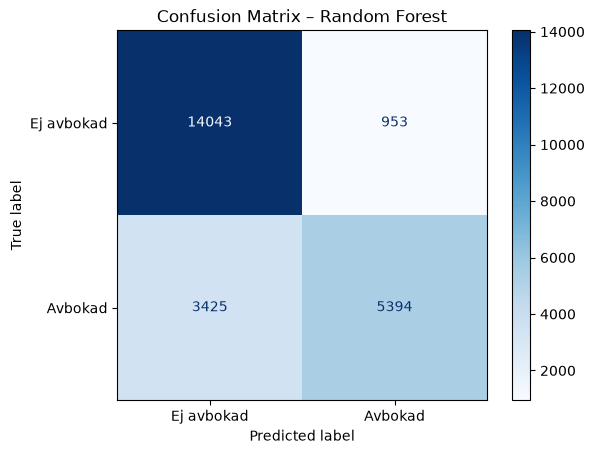

In [32]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    ConfusionMatrixDisplay
)

# Träna slutmodellen
rf_pipeline.fit(X_train, y_train)

# Förutsägelser på testdata
y_pred = rf_pipeline.predict(X_test)
y_proba = rf_pipeline.predict_proba(X_test)[:, 1]

# Utvärdera
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1-score:", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba), 4))

# Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Ej avbokad", "Avbokad"],
    cmap="Blues"
)

plt.title("Confusion Matrix – Random Forest")
plt.show()

#### Resultat

Random Forest uppnår följande resultat på testdata:

- Accuracy: 81,62 %
- Precision: 84,99 %
- Recall: 61,16 %
- F1-score: 71,13 %
- ROC-AUC: 0,9054

Modellen identifierade 5 394 faktiska avbokningar men missade 3 425. Dessutom klassificerades 953 bokningar felaktigt som avbokade.

Resultaten ligger nära cross-validation, vilket tyder på god generaliseringsförmåga. Modellens främsta svaghet är att den fortfarande missar en betydande andel av avbokningarna.

### Spara modellen för Streamlit

Den färdigtränade Random Forest-modellen sparas med Joblib för att användas i en webbaserad Streamlit-app.

Modellen sparas tillsammans med information om vilka features den behöver och standardvärden för dessa.

In [33]:
import joblib

# Standardvärden baserade på träningsdata
numeric_defaults = X_train[numeric_features].median().to_dict()

categorical_defaults = {
    col: X_train[col].mode().iloc[0]
    for col in categorical_features
}

# Samla modell och information
model_bundle = {
    "model": rf_pipeline,
    "feature_columns": X_train.columns.tolist(),
    "numeric_defaults": numeric_defaults,
    "categorical_defaults": categorical_defaults
}

# Spara modellen
joblib.dump(model_bundle, "hotel_booking_model.joblib")

print("Modellen har sparats!")
print("Antal features:", len(model_bundle["feature_columns"]))

Modellen har sparats!
Antal features: 18


In [34]:
import streamlit
import sklearn
import pandas
import joblib
import numpy
from pathlib import Path

requirements = f"""streamlit=={streamlit.__version__}
scikit-learn=={sklearn.__version__}
pandas=={pandas.__version__}
joblib=={joblib.__version__}
numpy=={numpy.__version__}
"""

Path("requirements.txt").write_text(requirements)

print(requirements)
print("requirements.txt har skapats!")

streamlit==1.58.0
scikit-learn==1.9.0
pandas==3.0.3
joblib==1.5.3
numpy==2.4.6

requirements.txt har skapats!


## Slutsats och projektlänkar

Projektet har utvecklat och jämfört Logistic Regression och Random Forest för att förutsäga hotellavbokningar.

Random Forest valdes som slutmodell och uppnådde följande resultat på testdata:

- Accuracy: 81,62 %
- Precision: 84,99 %
- Recall: 61,16 %
- F1-score: 71,13 %
- ROC-AUC: 0,9054

Modellen visar god prediktionsförmåga, men missar fortfarande en del faktiska avbokningar.

Extern helgdagsdata från Nager.Date API undersöktes men gav ingen betydande förbättring.

### Streamlit App

En interaktiv webbapp har utvecklats och publicerats på Streamlit Community Cloud.

[Öppna Hotel Cancellation Predictor](https://hotel-booking-predictor-nackademin.streamlit.app/)

Användaren fyller i bokningsinformation och klickar på **Beräkna avbokningsrisk** för att få modellens uppskattade sannolikhet för avbokning.

Appen är en demonstration baserad på historiska hotellbokningar från Portugal (2015–2017).

### GitHub

[Projektets GitHub-repository](https://github.com/GiantMovement/hotel-booking-cancellation-prediction)

Repositoryt innehåller notebooken, Streamlit-appen, den tränade modellen och installationsinstruktioner.